# Posidonia oceanica mapping from AUV video

This notebook runs the seagrass pipeline on a GoPro video and its `.srt` log (GPS position, depth `imm.` and altitude `alt.`):

1. **Enhance** the video with the *natural* method: haze and green cast removed (Sea-thru style, tuned for seagrass), sand balanced to beige.
2. **Detect** *Posidonia oceanica* and rock (and, with v12 / v13, debris such as tyres and plastic) with a trained YOLO11s-seg model (the **latest** by default; v8 to v13 to choose from).
3. **Map** the coverage: every analysed frame is placed on the seabed with the GPS and the camera geometry, giving coverage rasters (GeoTIFF) and polygons (GeoPackage / shapefile).

**How to use it:** run the cells from top to bottom (Shift + Enter). Each step has a settings panel; change the values, then run the cell below it. Each run's results go into a folder of their own, `results/<date>_<time>_<video>/` (step 1 starts a new one). Two 30 s samples are included in `input/`: `GX010287_sample.mp4` (dive GX010287, 1:30-2:00: seagrass and rock, 4 to 5.5 m deep) and `GX010175_sample.mp4` (dive GX010175, 1:20-1:50: a seagrass meadow with sand patches in very shallow, green water, about 1 m deep).

**On Binder:** there is no GPU, so everything runs on the CPU. Each 30 s sample takes about 8 to 10 minutes in total (enhancement ~4 min, detection ~3 min, map under 1 min). For your own videos, use short clips (under 1 to 2 minutes) or set start / end. A Binder session is deleted when you close it or after about 10 minutes without activity, so download your results at the end (last cell).

In [ ]:
import sys
sys.path.insert(0, ".code")
from pipeline import *

check_environment()

Python 3.13.15, PyTorch 2.6.0+cu124, OpenCV 5.0.0
CPU cores: 16, GPU: NVIDIA GeForce RTX 4060 Laptop GPU
ffmpeg: C:\Users\nikol\AppData\Roaming\Python\Python313\site-packages\imageio_ffmpeg\binaries\ffmpeg-win-x86_64-v7.1.exe
Videos in input/: GX010175_sample.mp4, GX010287_sample.mp4


## 0. Choose the video

Pick a video from `input/` (it starts on the one used last, at first `GX010287_sample.mp4`). Its `.srt` log must have the same name (e.g. `dive.mp4` + `dive.srt`).

To use your own video, upload it with the button (small files) or drag the video and its `.srt` into the `input/` folder in the file browser on the left (big files), then press **Refresh**. You can also give a direct download link.

In [2]:
video = choose_video()

## 1. Enhance the video (natural method)

- **Distance to the seabed**: *flat seabed* uses the altitude from the `.srt` (fast). *Depth Anything V2* estimates the distance of every pixel from the image, which handles slopes, rocks and open water better; it is several times slower on the CPU, downloads its model (~100 MB) on first use, and the output is named `..._enhanced_natural_depth.mp4`.
- **Strength**: 1 = full correction; 0.75 suits very green, shallow videos.
- **Haze removal**: 1 = as fitted from the video. Above 1 gives a clearer picture, but the darkest seagrass can turn grey-purple.
- **Distance colour balance**: the far (top) part of the frame comes out yellower, browner or greener and flatter than the near part, because its light travelled further through the water. This gives the far sand and rock the colour, brightness and detail of the near seabed (1 = full, 0 = off). With it, *flat seabed* is usually as good as Depth Anything and 4x faster.
- **Local contrast**: brings out the texture of seagrass, rock and sand (0 = off, 2 = clearly sharper). It only changes brightness, not colour, and makes the picture a little darker; the output is named `..._lc2.mp4` etc.
- **Shadow balance**: keeps dark seagrass olive instead of pink or mauve.
- **Remove floating particles** and **Removal method** (the method list appears when the box is ticked): removes the floating particles (the correction turns them into orange streaks). *median* lines up the 2 frames before and after each frame and takes the middle value of every pixel: a drifting particle is missing from most of them, so it disappears; the seabed gets slightly softer and fish fade. It removed about 9 in 10 moving particles on GX010175, is about 3x slower, and the output is named `..._pmedian5.mp4`. *bright* (`_pbright5`) replaces only what is brighter than in those frames: sharper seabed, more particles left; *blur* (`_pblur`) is fast but can leave smudges. Use the same setting for the videos you detect on as for the frames a model was trained on.
- **Preview only**: fits the water and saves a before/after picture without making the video (fast, for trying settings).

Untick *Enhance the video* to run the detection on the original instead.

In [3]:
enhance = enhance_settings()

Results of this run: results/2026-11-08_120353_GX010287_sample/


Video:  input\GX010287_sample.mp4 (900 frames, 0.5 min)
Method: natural, camera tilt 64 deg, vertical FOV 75.3 deg
SRT:    input\GX010287_sample.srt: 60 entries, 30 s
        altitude 4.3-5.1 m, depth 4.1-5.4 m
Fitting the water on 60 sample frames...
Camera colour: 8 of 60 sample frames have a different camera white balance; left out of the fit, corrected less in the video
Haze lowered to 0.79 of the fitted curve
Shadow balance: haze removed R/G/B x [0.77 0.71 1.  ] (darkest 20 % to dark olive)
Distance colour balance: strength 1
Saved fit:     results\2026-11-08_120353_GX010287_sample\enhancement\GX010287_sample_enhance_natural_fit.png
Saved values:  results\2026-11-08_120353_GX010287_sample\enhancement\GX010287_sample_enhance_natural.json
Saved preview: results\2026-11-08_120353_GX010287_sample\enhancement\GX010287_sample_enhance_natural_preview.jpg (top = original, then enhanced)
Reading / writing: ffmpeg (NVIDIA decoder + h264_nvenc), correction on the GPU
Saved enhanced video: re

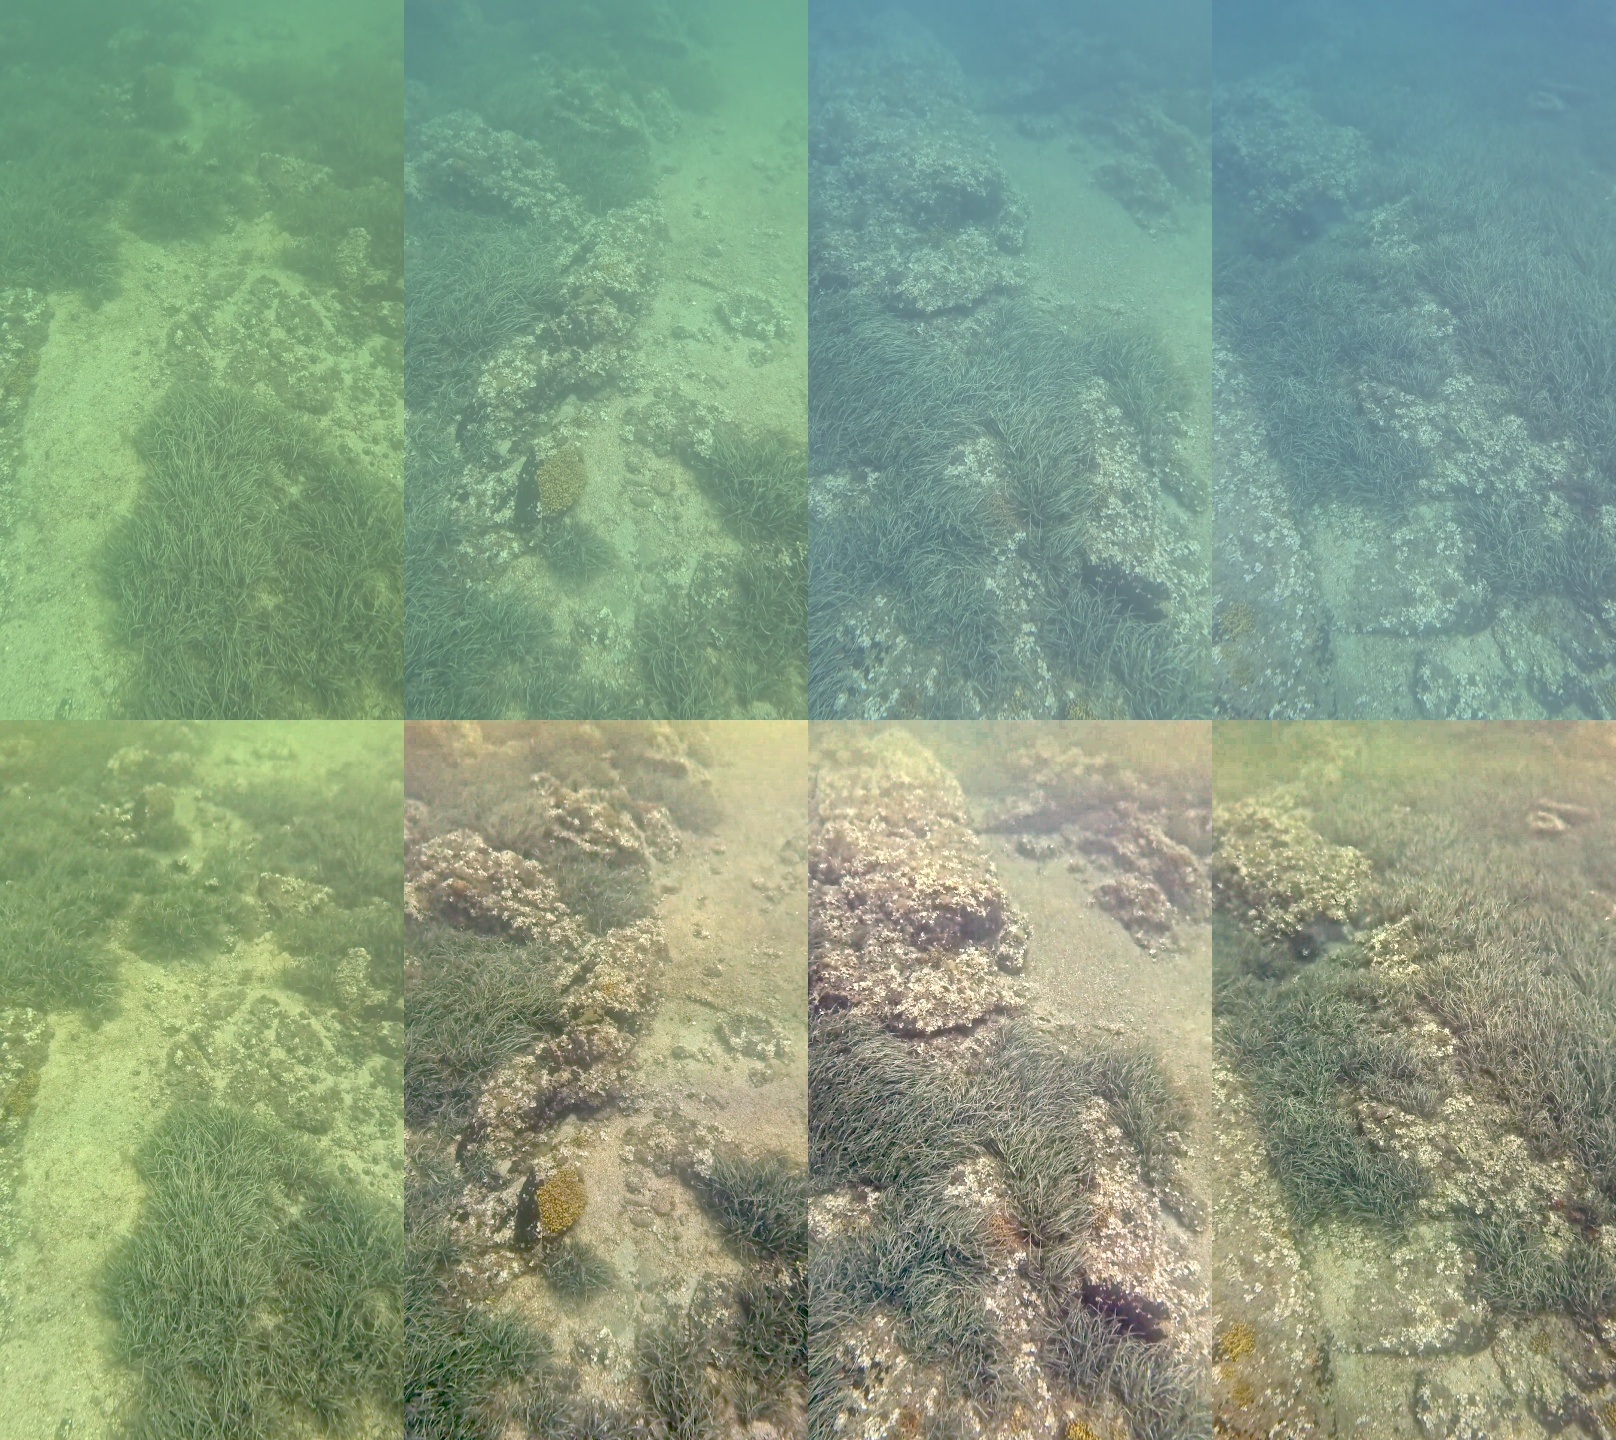

Enhanced video: results/2026-11-08_120353_GX010287_sample/enhancement/GX010287_sample_enhanced_natural.mp4


In [4]:
run_enhance(video, enhance)

## 2. Detect the seagrass

The model finds *posidonia_oceanica* and *rock*. It is run on the enhanced video (or on the original if step 1 was skipped).

- **Model**: the trained models in `models/` (the newest, shown as *latest (vN)*, is preselected), with their classes, the dives they were trained on and their mask mAP50 (measured on different validation frames for each model, so compare them with care):
  - **v8**: posidonia, rock; GX010287. Use it for GX010287-like videos.
  - **v10**: an older GX010287 model that scores lower.
  - **v11**: posidonia, rock; GX010287 + GX010175. The best for GX010175: it found seagrass in 93 % of the frames of a meadow stretch, against 30 % for v8.
  - **v12**, **v13**: also detect **debris** (tyres, plastic). v13 learned the debris much better, but on GX010175 it finds less seagrass than v11, because some of its training frames had only the debris labelled. Use them to find debris, and v11 for the seagrass.
  - v11 to v13 were trained on GX010175 frames enhanced with *Remove floating particles* (method *median*): enhance GX010175 videos the same way for them.
- **Confidence**: lower finds more faint seagrass but gives more false detections.
- **Every n-th frame**: 2 = half of the frames (twice as fast); the saved video then plays at half the frame rate.
- **Live view updates**: while it runs, the cell below shows the latest annotated frame with what was found in it (like the detection window of the desktop version). Press the stop button (■) in the toolbar to stop the detection.

In [5]:
detect = detect_settings()

class,areas,best conf,cover of the frame
posidonia_oceanica,2,0.92,60 %
rock,4,0.78,16 %
debris,0,0.00,0 %

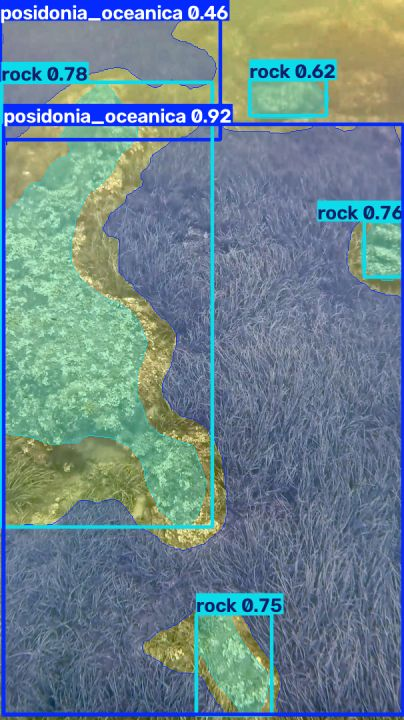

Video: results\2026-11-08_120353_GX010287_sample\enhancement\GX010287_sample_enhanced_natural.mp4
Model: models\v13\model.pt (YOLO), classes posidonia_oceanica, rock, debris
900 frames at 29.97 fps; the model runs on every 2. frame (450 frames)
Saved annotated video: results\2026-11-08_120353_GX010287_sample\prediction\GX010287_sample_enhanced_natural_v13_prediction.mp4
Saved per-frame detections: results\2026-11-08_120353_GX010287_sample\prediction\GX010287_sample_enhanced_natural_v13_detections.csv
Processed 450 frames in 1.2 min
--- detect_video.py finished in 1.3 min
Some frames of the annotated video:


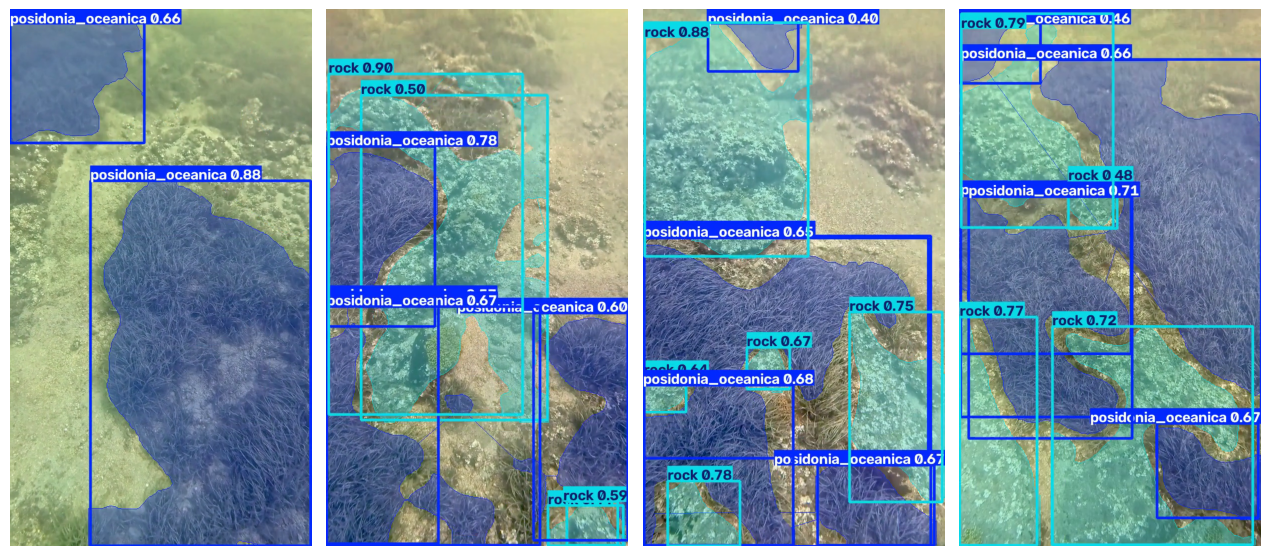

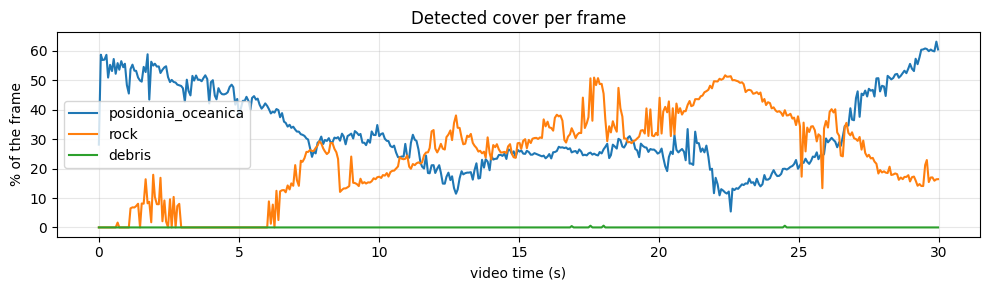

Average % of the frame: posidonia_oceanica 32.5 %, rock 24.1 %, debris 0.0 %
Annotated video: results\2026-11-08_120353_GX010287_sample\prediction\GX010287_sample_enhanced_natural_v13_prediction.mp4 (play it below, or download it)


In [6]:
run_detect(detect)

### Browse the detections

Step through the annotated video frame by frame with the slider, or press play. On the right: the areas found in that frame, the best confidence and the % of the frame each class covers, with the frame's place on the cover chart.

In [7]:
browse_detections()

## 3. Coverage map

Every analysed frame is put on the seabed using the GPS track (direction of travel = camera direction), the altitude from the `.srt` and the camera geometry (flat seabed assumed). Each map cell gets the % of the frames that saw it in which the class was detected.

- **Seconds between frames**: smaller = more frames, slower.
- **Cell size**: 0.25 m by default.
- **Max range**: pixels farther from the camera than this are not used (they are small and less accurate).
- **Min. views per cell**: cells seen fewer times stay empty.
- **Class threshold**: a cell becomes a polygon of that class when at least this % of its views found the class.
- **Camera tilt / FOV**: GoPro HERO13 4K Wide behind a flat port, portrait video. Change them for another camera mount.

In [8]:
coverage = coverage_settings()

Video:  results\2026-11-08_120353_GX010287_sample\enhancement\GX010287_sample_enhanced_natural.mp4
Model:  models\v13\model.pt, classes posidonia_oceanica, rock, debris
SRT:    results\2026-11-08_120353_GX010287_sample\enhancement\GX010287_sample_enhanced_natural.srt: 60 entries, 30 s
GPS:    60 positions, UTM zone 35 (EPSG:32635), median speed 1.09 m/s, altitude 4.3-5.1 m
Camera: tilt 64 deg, vertical FOV 75.3 deg, horizontal FOV 46 deg; mapping up to 8 m from the camera
Grid:   163 x 175 cells of 0.25 m (41 x 44 m)
Analysed 59 frames in 0.1 min
Saved coverage rasters: results\2026-11-08_120353_GX010287_sample\coverage\GX010287_sample_enhanced_natural_v13_<class>_coverage.tif  (0-100 %, 0.25 m cells, EPSG:32635)
Saved check mosaic:     results\2026-11-08_120353_GX010287_sample\coverage\GX010287_sample_enhanced_natural_v13_mosaic.tif  (frames placed on the map, to check the alignment)
Saved polygons:         results\2026-11-08_120353_GX010287_sample\coverage\GX010287_sample_enhanced_na

c:\Users\nikol\Desktop\YOLO_video\posidonia_binder\pipeline.py:695: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  gpd.read_file(gpkg, layer=cls).boundary.plot(ax=ax, color="k", linewidth=0.6)


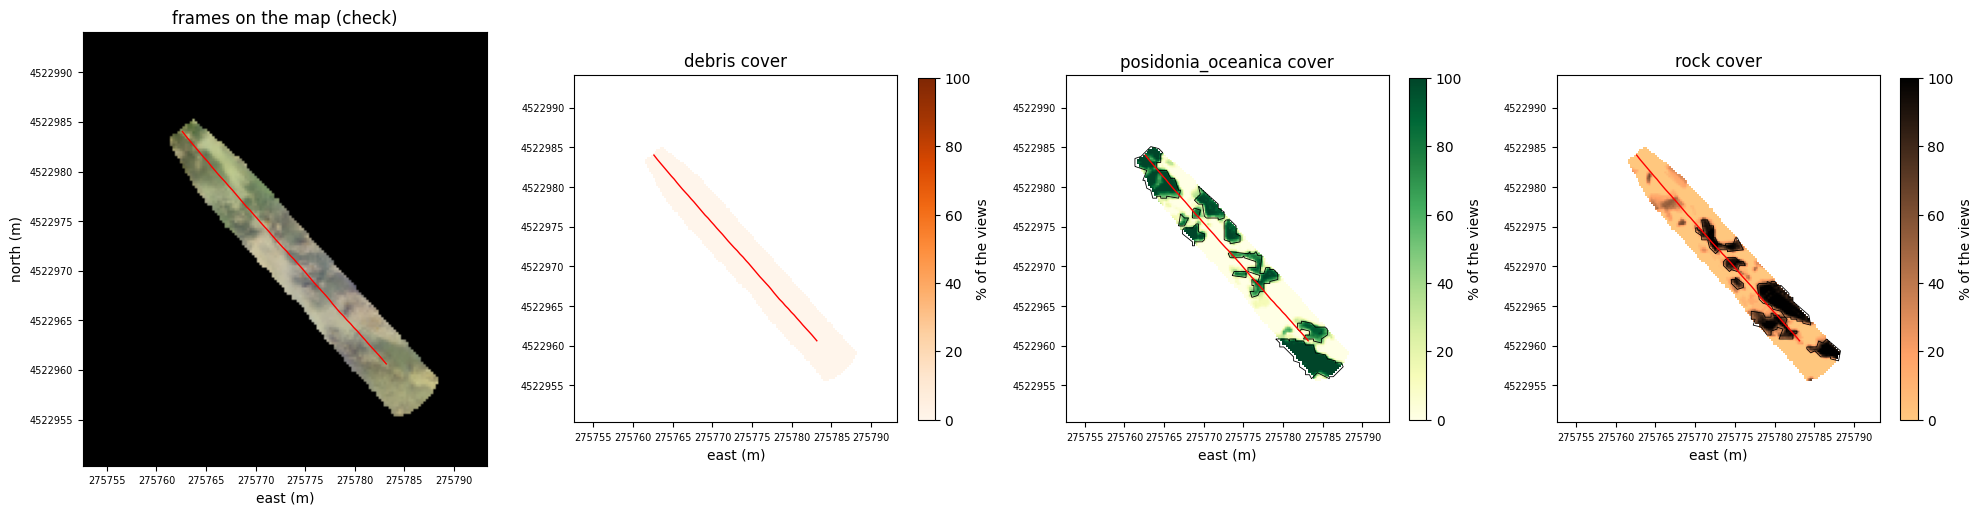

Surveyed area: 198 m2


,class,patches,area_m2,share_of_surveyed_%
0,debris,0,0.0,0.0
1,posidonia_oceanica,10,72.1,36.3
2,rock,6,44.3,22.3



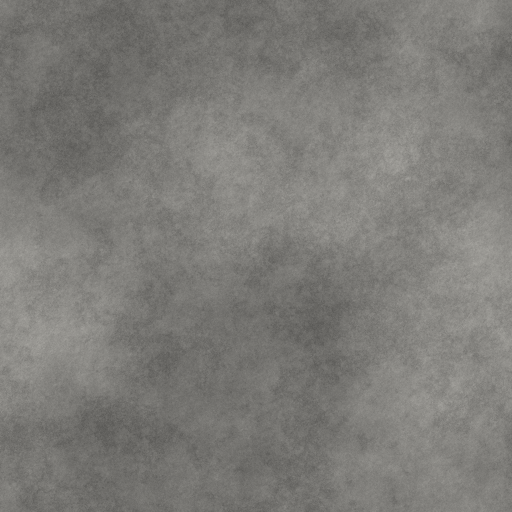

In [9]:
run_coverage(coverage)

The maps are in the run's folder, `results/<run>/coverage/`:
- `<video>_<model>_<class>_coverage.tif` (e.g. `GX010175_sample_enhanced_natural_pmedian5_v13_...`): cover in % per cell (GeoTIFF, UTM)
- `<video>_<model>_coverage.gpkg`: polygons per class, the surveyed area and the camera track (open in QGIS: the layers come up with the styles in `styles/`)
- `<video>_<model>_<class>.shp`: the same polygons as shapefiles (with their style as `.qml`)
- `<video>_<model>_mosaic.tif`: the video frames placed on the map, to check the alignment

The run's folder also has `enhancement/` (the enhanced video, preview and fit chart), `prediction/` (the annotated video and the per-frame table) and `settings.ini` (the settings used).

## 4. Download the results

Binder deletes the session when you close it. Choose the **runs** (the newest is preselected) and **what** to include (enhanced videos, previews, detection videos, detection tables, coverage maps, settings), each with an **all** option; Ctrl + click or Shift + click chooses several. Then press **Make the zip** and download `results.zip`. Leave the videos out for a small zip.

In [10]:
zip_results()